# Source data analysis

**Goal:** understand the Synthea FHIR files well enough to write the silver-layer code in the Glue job.

**What this notebook answers**
1. What files did Synthea produce, and how big are they?
2. What does one patient file look like inside?
3. Which resource types exist, and which ones do we need?
4. Which encounter classes exist (needed for the inpatient / ED KPIs)?
5. How do records reference each other, and how do we turn a reference into a plain id?
6. Can every silver column be filled from the raw fields? Do the keys join?
7. Did the batch splitter distribute the files correctly?

The matching written reference is `docs/build_notes/data_dictionary.md`.

## 1. Setup

In [1]:
import collections
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

# Works wherever Jupyter starts inside the project: walk up to the folder that holds pyproject.toml
ROOT = next(path for path in [Path.cwd(), *Path.cwd().parents] if (path / "pyproject.toml").exists())
FHIR_DIR = ROOT / "output" / "fhir"          # raw Synthea output
LANDING_DIR = ROOT / "data" / "landing"      # the 10 daily batches

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)

## 2. Files Synthea produced

One bundle per patient, plus one bundle of hospitals and one of practitioners.

In [2]:
all_files = sorted(FHIR_DIR.glob("*.json"))
hospital_file = next(f for f in all_files if f.name.startswith("hospitalInformation"))
practitioner_file = next(f for f in all_files if f.name.startswith("practitionerInformation"))
patient_files = [f for f in all_files if f not in (hospital_file, practitioner_file)]

total_mb = sum(f.stat().st_size for f in all_files) / 1e6
print(f"patient files      : {len(patient_files)}")
print(f"hospital file      : {hospital_file.name}")
print(f"practitioner file  : {practitioner_file.name}")
print(f"total size         : {total_mb:,.1f} MB")

patient files      : 341
hospital file      : hospitalInformation1792681729651.json
practitioner file  : practitionerInformation1792681729651.json
total size         : 722.6 MB


## 3. Anatomy of one patient file

A FHIR **Bundle** is a wrapper. Its `entry` list holds the records; each record is in `entry[].resource`
and its `resourceType` says what kind of record it is.

In [3]:
def load_bundle(path):
    with open(path, encoding="utf-8") as f:
        return json.load(f)


def resources(bundle):
    """Yield the records (resources) inside a bundle."""
    for entry in bundle["entry"]:
        yield entry["resource"]


sample = load_bundle(patient_files[0])
print("bundle resourceType:", sample["resourceType"], "| type:", sample["type"])
print("number of entries  :", len(sample["entry"]))
print("keys of one entry  :", list(sample["entry"][0].keys()))
print("record types in this file:")
print(pd.Series([r["resourceType"] for r in resources(sample)]).value_counts().to_string())

bundle resourceType: Bundle | type: transaction
number of entries  : 320
keys of one entry  : ['fullUrl', 'resource', 'request']
record types in this file:
Observation                 71
Procedure                   65
DiagnosticReport            32
Claim                       24
ExplanationOfBenefit        24
Condition                   23
Encounter                   19
DocumentReference           19
SupplyDelivery              12
Immunization                 6
MedicationRequest            5
Device                       4
CareTeam                     3
CarePlan                     3
Medication                   3
MedicationAdministration     3
ImagingStudy                 2
Patient                      1
Provenance                   1


## 4. One pass over all patient files

We read every file once and keep only what we need:
resource counts for every type, plus flat rows for Patient, Encounter and Condition
(a pandas preview of what the Spark job will produce in the Glue job).

**Helpers**
- `first(list)` returns the first item or an empty dict. FHIR stores many values in lists.
- `resolve_ref(reference)` turns a FHIR reference into a plain id (section 6).

In [4]:
def first(items, default=None):
    """First element of a list, or `default` if the list is missing or empty."""
    return items[0] if items else (default if default is not None else {})


def resolve_ref(reference):
    """Turn a FHIR reference into a plain id.

    urn:uuid:<id>                        -> <id>
    Organization?identifier=<system>|<id> -> <id>   (conditional reference)
    Practitioner?identifier=<system>|<npi> -> <npi>
    """
    if not reference:
        return None
    if reference.startswith("urn:uuid:"):
        return reference[len("urn:uuid:"):]
    if "|" in reference:
        return reference.rsplit("|", 1)[1]
    return reference.split("/")[-1]


def patient_row(r):
    address = first(r.get("address"))
    return {
        "patient_id": r["id"],
        "gender": r.get("gender"),
        "birth_date": r.get("birthDate"),
        "deceased_datetime": r.get("deceasedDateTime"),
        "marital_status": first(r.get("maritalStatus", {}).get("coding")).get("code"),
        "city": address.get("city"),
        "state": address.get("state"),
        "postal_code": address.get("postalCode"),
    }


def encounter_row(r):
    type_coding = first(first(r.get("type")).get("coding"))
    reason_coding = first(first(r.get("reasonCode")).get("coding"))
    practitioner_ref = first(r.get("participant")).get("individual", {}).get("reference")
    return {
        "encounter_id": r["id"],
        "patient_id": resolve_ref(r["subject"]["reference"]),
        "status": r["status"],
        "encounter_class": r["class"]["code"],
        "type_code": type_coding.get("code"),
        "type_display": type_coding.get("display"),
        "start_ts": r["period"]["start"],
        "end_ts": r["period"].get("end"),
        "organization_id": resolve_ref(r.get("serviceProvider", {}).get("reference")),
        "practitioner_id": resolve_ref(practitioner_ref),
        "reason_code": reason_coding.get("code"),
        "reason_display": reason_coding.get("display"),
    }


def condition_row(r):
    coding = first(r["code"]["coding"])
    return {
        "condition_id": r["id"],
        "patient_id": resolve_ref(r["subject"]["reference"]),
        "encounter_id": resolve_ref(r.get("encounter", {}).get("reference")),
        "code": coding.get("code"),
        "display": coding.get("display"),
        "clinical_status": first(r["clinicalStatus"]["coding"]).get("code"),
        "onset_ts": r.get("onsetDateTime"),
        "abatement_ts": r.get("abatementDateTime"),
    }


resource_counts = collections.Counter()
patient_rows, encounter_rows, condition_rows = [], [], []

for path in patient_files:
    for r in resources(load_bundle(path)):
        rtype = r["resourceType"]
        resource_counts[rtype] += 1
        if rtype == "Patient":
            patient_rows.append(patient_row(r))
        elif rtype == "Encounter":
            encounter_rows.append(encounter_row(r))
        elif rtype == "Condition":
            condition_rows.append(condition_row(r))

patients = pd.DataFrame(patient_rows)
encounters = pd.DataFrame(encounter_rows)
conditions = pd.DataFrame(condition_rows)
print(f"patients={len(patients):,}  encounters={len(encounters):,}  conditions={len(conditions):,}")

patients=341  encounters=10,876  conditions=7,243


## 5. Which resource types exist?

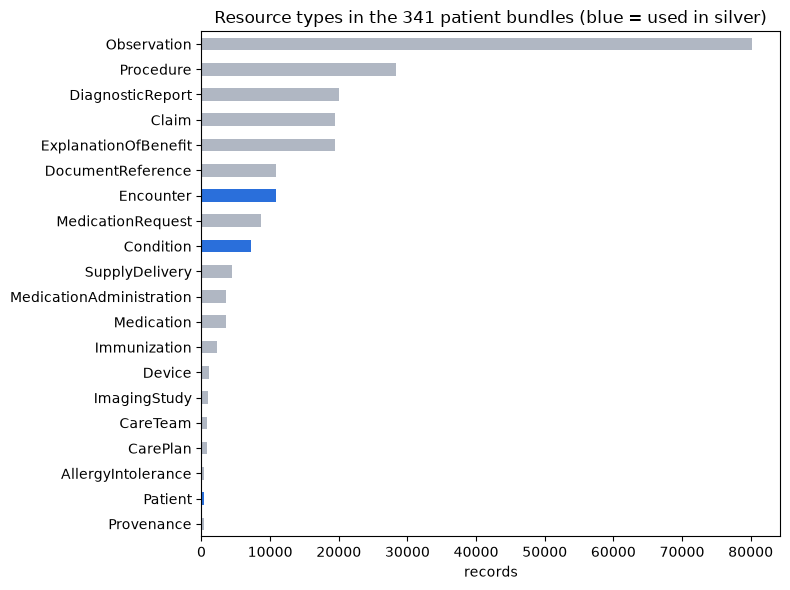

In [5]:
counts = pd.Series(resource_counts).sort_values(ascending=False)
used = {"Patient", "Encounter", "Condition"}   # Organization / Practitioner come from the other two files

ax = counts.plot.barh(figsize=(8, 6), color=["#2a6fdb" if t in used else "#b0b7c3" for t in counts.index])
ax.invert_yaxis()
ax.set_xlabel("records")
ax.set_title("Resource types in the 341 patient bundles (blue = used in silver)")
plt.tight_layout()
plt.show()

Only a handful of the 20 resource types matter for our KPIs: **Patient, Encounter, Condition**
(plus Organization and Practitioner from the shared files). `Observation`, the biggest type, is ignored for now.

## 6. Reference formats

Records point to each other with a `reference`. Synthea uses two styles, so we need the helper `resolve_ref`.

In [6]:
sample_encounter = next(r for r in resources(sample) if r["resourceType"] == "Encounter")
print("subject         :", sample_encounter["subject"]["reference"])
print("serviceProvider :", sample_encounter["serviceProvider"]["reference"])
print("practitioner    :", sample_encounter["participant"][0]["individual"]["reference"])

# Unit-style checks: each format must come back as a plain id.
assert resolve_ref("urn:uuid:abc-123") == "abc-123"
assert resolve_ref("Organization?identifier=https://github.com/synthetichealth/synthea|abc-123") == "abc-123"
assert resolve_ref("Practitioner?identifier=http://hl7.org/fhir/sid/us-npi|9999982090") == "9999982090"
assert resolve_ref(None) is None
print("resolve_ref OK")

subject         : urn:uuid:f75caf9c-ba51-5e74-1461-a54b3d07b53f
serviceProvider : Organization?identifier=https://github.com/synthetichealth/synthea|4bc0cc09-77e5-37f5-844d-64a6637cae54
practitioner    : Practitioner?identifier=http://hl7.org/fhir/sid/us-npi|9999999896
resolve_ref OK


**Note:** the practitioner reference holds an **NPI** (national provider number), not the Practitioner record's uuid.
Section 8 checks which column it joins to.

## 7. Encounter classes

The class decides what counts as inpatient (`IMP`) and emergency (`EMER`).

encounter_class
AMB     10135
EMER      373
IMP       283
HH         50
VR         35


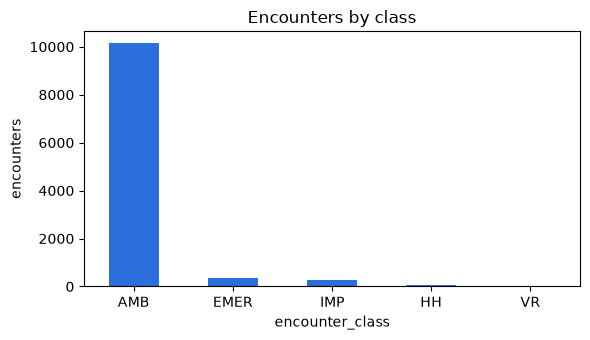

In [7]:
class_counts = encounters["encounter_class"].value_counts()
print(class_counts.to_string())

ax = class_counts.plot.bar(figsize=(6, 3.5), color="#2a6fdb")
ax.set_ylabel("encounters")
ax.set_title("Encounters by class")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

`AMB` ambulatory, `EMER` emergency, `IMP` inpatient (hospital stay), `HH` home health, `VR` virtual.
Inpatient is rare, so the readmission KPI will rest on a small number of stays.

## 8. Silver preview and join checks

Prototype of the silver tables. Timestamps have mixed UTC offsets (`+05:00`, `+06:00`, `+05:30`, `+06:30`),
so we parse them to UTC; the Glue job must make the same deliberate choice in Spark.

In [8]:
def read_reference_bundle(path):
    return list(resources(load_bundle(path)))


organizations = pd.DataFrame([
    {
        "organization_id": r["id"],
        "name": r.get("name"),
        "type": first(first(r.get("type")).get("coding")).get("code"),
        "city": first(r.get("address")).get("city"),
        "state": first(r.get("address")).get("state"),
        "postal_code": first(r.get("address")).get("postalCode"),
    }
    for r in read_reference_bundle(hospital_file) if r["resourceType"] == "Organization"
])

practitioners = pd.DataFrame([
    {
        "practitioner_id": r["id"],
        "npi": first(r.get("identifier")).get("value"),
        "full_name": " ".join(first(r.get("name")).get("given", []) + [first(r.get("name")).get("family", "")]),
        "gender": r.get("gender"),
    }
    for r in read_reference_bundle(practitioner_file) if r["resourceType"] == "Practitioner"
])

print(f"organizations={len(organizations)}  practitioners={len(practitioners)}")
encounters.head(3)

organizations=521  practitioners=521


,encounter_id,patient_id,status,encounter_class,type_code,type_display,start_ts,end_ts,organization_id,practitioner_id,reason_code,reason_display
0,f75caf9c-ba51-5e74-b210-6dc056eeb080,f75caf9c-ba51-5e74-1461-a54b3d07b53f,finished,AMB,185345009,Encounter for symptom (procedure),1994-08-21T16:21:16+05:00,1994-08-21T16:36:16+05:00,4bc0cc09-77e5-37f5-844d-64a6637cae54,9999999896,36971009,Sinusitis (disorder)
1,f75caf9c-ba51-5e74-d252-beb813b4c6c5,f75caf9c-ba51-5e74-1461-a54b3d07b53f,finished,AMB,410620009,Well child visit (procedure),1997-03-05T02:21:16+05:00,1997-03-05T02:36:16+05:00,1d45436f-15a9-326e-a452-2e9ffc9fc5e5,9999969295,NaN,NaN
2,f75caf9c-ba51-5e74-dcf3-115352154dab,f75caf9c-ba51-5e74-1461-a54b3d07b53f,finished,AMB,162673000,General examination of patient (procedure),1998-03-11T02:21:16+05:00,1998-03-11T03:10:20+05:00,1d45436f-15a9-326e-a452-2e9ffc9fc5e5,9999969295,NaN,NaN


In [9]:
# Parse timestamps to UTC and compute length of stay for inpatient encounters
encounters["start_utc"] = pd.to_datetime(encounters["start_ts"], utc=True)
encounters["end_utc"] = pd.to_datetime(encounters["end_ts"], utc=True)
encounters["los_hours"] = (encounters["end_utc"] - encounters["start_utc"]).dt.total_seconds() / 3600

print("encounters with end before start:", int((encounters["los_hours"] < 0).sum()))
print("duplicate encounter ids         :", int(encounters["encounter_id"].duplicated().sum()))
print("\nLength of stay (hours) by class:")
print(encounters.groupby("encounter_class")["los_hours"].describe().round(1).to_string())

encounters with end before start: 0
duplicate encounter ids         : 0

Length of stay (hours) by class:
                   count   mean    std   min   25%    50%    75%     max
encounter_class                                                         
AMB              10135.0    1.3    7.8   0.2   0.2    0.7    1.2   733.0
EMER               373.0   10.1   62.0   1.0   1.0    1.0    1.0   748.5
HH                  50.0  269.6  306.0   0.2   0.2  127.2  570.6  1176.2
IMP                283.0  146.6  212.9  24.0  42.5  103.9  174.5  2280.2
VR                  35.0    0.5    0.5   0.2   0.2    0.2    0.6     1.9


In [10]:
# Do the keys join?
print("encounter -> patient      :", f"{encounters['patient_id'].isin(patients['patient_id']).mean():.1%}")
print("encounter -> organization :", f"{encounters['organization_id'].isin(organizations['organization_id']).mean():.1%}")
print("encounter -> practitioner (by npi)         :", f"{encounters['practitioner_id'].isin(practitioners['npi']).mean():.1%}")
print("encounter -> practitioner (by practitioner_id):", f"{encounters['practitioner_id'].isin(practitioners['practitioner_id']).mean():.1%}")
print("condition -> encounter    :", f"{conditions['encounter_id'].isin(encounters['encounter_id']).mean():.1%}")

encounter -> patient      : 100.0%
encounter -> organization : 100.0%
encounter -> practitioner (by npi)         : 100.0%
encounter -> practitioner (by practitioner_id): 0.0%


condition -> encounter    : 100.0%


**Reading the result:** the practitioner reference only joins through `npi`, never through `practitioner_id`.
Decision for the Glue job and the gold layer: key the practitioner dimension on NPI.

## 9. Check the batches

`split_batches.py` should have placed every file in exactly one batch, with the two shared files in `batch_01`.

In [11]:
# Batches 1-4 are in data/landing; the rest were set aside in data/landing_extra (smaller project scope)
batch_dirs = sorted(LANDING_DIR.glob("batch_*")) + sorted((ROOT / "data" / "landing_extra").glob("batch_*"))
rows = []
for d in batch_dirs:
    files = list(d.glob("*.json"))
    rows.append({"batch": d.name, "files": len(files), "MB": round(sum(f.stat().st_size for f in files) / 1e6, 1)})
batch_summary = pd.DataFrame(rows)
display(batch_summary)

landed_names = [f.name for d in batch_dirs for f in d.glob("*.json")]
assert len(batch_dirs) == 10, "expected 10 batches"
assert len(landed_names) == len(set(landed_names)) == len(all_files), "a file is missing or duplicated"
assert {f.name for f in (hospital_file, practitioner_file)} <= {f.name for f in (LANDING_DIR / "batch_01").glob("*.json")}
print("batches OK: every source file is in exactly one batch")

,batch,files,MB
0,batch_01,37,110.8
1,batch_02,34,45.8
2,batch_03,34,67.1
3,batch_04,34,71.3
4,batch_05,34,59.9
5,batch_06,34,94.1
6,batch_07,34,77.6
7,batch_08,34,68.0
8,batch_09,34,56.5
9,batch_10,34,71.7


batches OK: every source file is in exactly one batch


## 10. Findings

| # | Finding | Used in |
|---|---|---|
| 1 | 341 patient bundles + 1 hospital + 1 practitioner file; about 723 MB | the AWS foundation upload |
| 2 | Only Patient, Encounter, Condition (+ the two shared files) feed silver | the Glue job |
| 3 | Encounter classes: AMB, EMER, IMP, HH, VR; 283 inpatient stays | the gold layer KPIs |
| 4 | References use two formats; `resolve_ref` handles both | the Glue job (`fhir_utils.py`) |
| 5 | Practitioner joins on NPI, not uuid | the Glue job and the gold layer model |
| 6 | Timestamps have mixed offsets; choose one time zone in Spark | the Glue job |